In [2]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    # expit:이진분류,softmax:다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from sklearn.model_selection import cross_validate
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV

In [3]:
# 데이터 가져오기
wine = pd.read_csv('data/wine.csv')
wine.head(2)

,alcohol,sugar,pH,class
0,9.4,1.9,3.51,0.0
1,9.8,2.6,3.20,0.0


In [4]:
wine.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   alcohol  6497 non-null   float64
 1   sugar    6497 non-null   float64
 2   pH       6497 non-null   float64
 3   class    6497 non-null   float64
dtypes: float64(4)
memory usage: 203.2 KB


In [5]:
wine.describe()

,alcohol,sugar,pH,class
count,6497.000000,6497.000000,6497.000000,6497.000000
mean,10.491801,5.443235,3.218501,0.753886
std,1.192712,4.757804,0.160787,0.430779
min,8.000000,0.600000,2.720000,0.000000
25%,9.500000,1.800000,3.110000,1.000000
50%,10.300000,3.000000,3.210000,1.000000
75%,11.300000,8.100000,3.320000,1.000000
max,14.900000,65.800000,4.010000,1.000000


<Axes: >

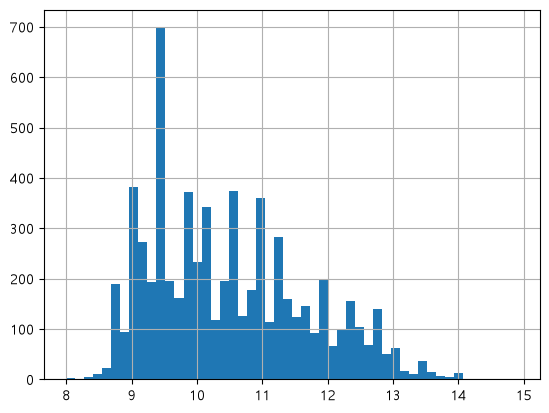

In [6]:
# 히스토그램 - 피처컬럼에 대한 분포도 볼수 있음.
wine['alcohol'].hist(bins=50)

<Axes: >

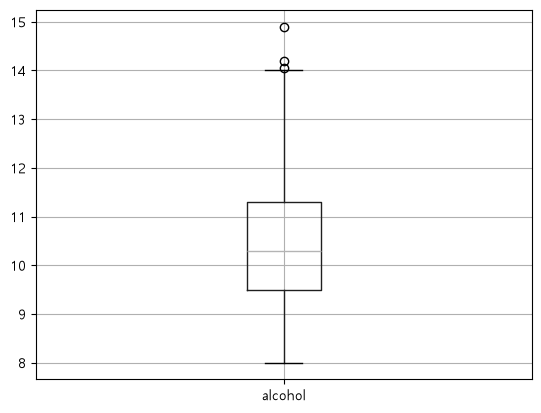

In [7]:
wine.boxplot(column=['alcohol'])

In [8]:
wine2 = wine[['alcohol', 'sugar', 'pH']]
wine2.head(2)

,alcohol,sugar,pH
0,9.4,1.9,3.51
1,9.8,2.6,3.20


In [9]:
def plot_hist(wine2):
    plt.rcParams['figure.figsize'] = [10,2]
    fig = plt.figure(1)  # 전체그래프 1개를 생성
    for i in range(len(wine2.columns)):
        ax = fig.add_subplot(1,3,i+1)
        plt.hist(wine2[wine2.columns[i]],bins=50)
        ax.set_title(wine2.columns[i])
    plt.show()    

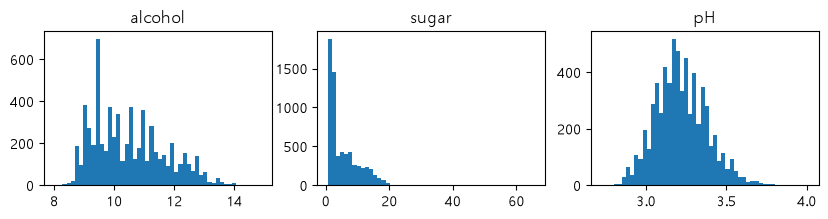

In [10]:
plot_hist(wine2)

데이터 전처리 작업
- None데이터 유무
- None 데이터를 어떻게 처리 할것인지 : 삭제,평균,0 대체
- 정규화작업을 해야 하는지
- 원핫인코딩 작업을 해야 하는지

In [11]:
# data,label 저장
data = wine[wine.columns[:-1]].values
label = wine['class'].values

# 데이터 분리
train_data,test_data,train_label,test_label = \
train_test_split(data,label,test_size=0.2,random_state=42)

In [12]:
for i in np.arange(0.0001,0.001,0.0001):
    dt = DecisionTreeClassifier(min_impurity_decrease=i, \
                                min_samples_split=2, max_depth=1, random_state=42)
    dt.fit(train_data,train_label)
    print(i)
    print('train정확도:', dt.score(train_data,train_label))
    print('test정확도:', dt.score(test_data,test_label))

0.0001
train정확도: 0.7579372715027901
test정확도: 0.7376923076923076
0.0002
train정확도: 0.7579372715027901
test정확도: 0.7376923076923076
0.00030000000000000003
train정확도: 0.7579372715027901
test정확도: 0.7376923076923076
0.0004
train정확도: 0.7579372715027901
test정확도: 0.7376923076923076
0.0005
train정확도: 0.7579372715027901
test정확도: 0.7376923076923076
0.0006000000000000001
train정확도: 0.7579372715027901
test정확도: 0.7376923076923076
0.0007000000000000001
train정확도: 0.7579372715027901
test정확도: 0.7376923076923076
0.0008
train정확도: 0.7579372715027901
test정확도: 0.7376923076923076
0.0009000000000000001
train정확도: 0.7579372715027901
test정확도: 0.7376923076923076


In [16]:
for i in np.arange(2,100,10):
    dt = DecisionTreeClassifier(min_impurity_decrease=i, \
                                min_samples_split=2, max_depth=2, random_state=42)
    dt.fit(train_data,train_label)
    print(i)
    print('train정확도:', dt.score(train_data,train_label))
    print('test정확도:', dt.score(test_data,test_label))

2
train정확도: 0.7579372715027901
test정확도: 0.7376923076923076
12
train정확도: 0.7579372715027901
test정확도: 0.7376923076923076
22
train정확도: 0.7579372715027901
test정확도: 0.7376923076923076
32
train정확도: 0.7579372715027901
test정확도: 0.7376923076923076
42
train정확도: 0.7579372715027901
test정확도: 0.7376923076923076
52
train정확도: 0.7579372715027901
test정확도: 0.7376923076923076
62
train정확도: 0.7579372715027901
test정확도: 0.7376923076923076
72
train정확도: 0.7579372715027901
test정확도: 0.7376923076923076
82
train정확도: 0.7579372715027901
test정확도: 0.7376923076923076
92
train정확도: 0.7579372715027901
test정확도: 0.7376923076923076


In [17]:
wine.columns

Index(['alcohol', 'sugar', 'pH', 'class'], dtype='str')

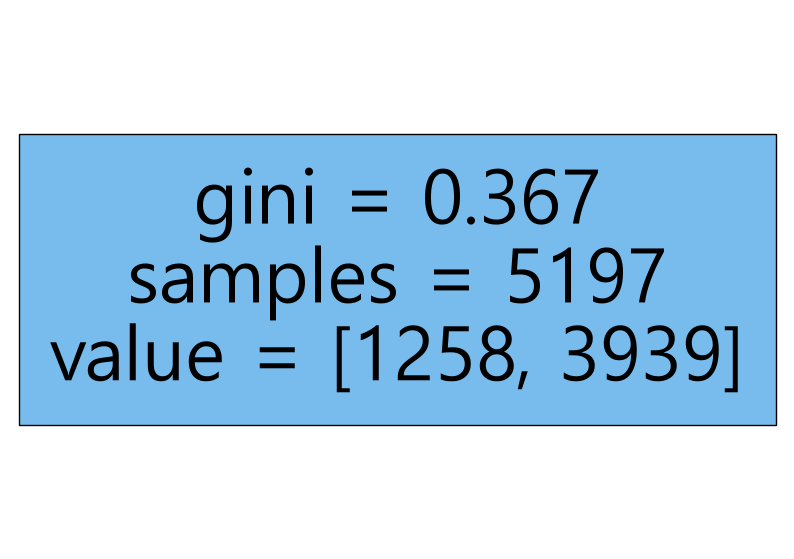

In [18]:
plt.figure(figsize=(10,7))
plot_tree(dt,max_depth=2,filled=True,feature_names=['alcohol','sugar','pH'])
plt.show()

In [23]:
print('train정확도:', dt.score(train_data,train_label))
print('test정확도:', dt.score(test_data,test_label))

train정확도: 0.996921300750433
test정확도: 0.8584615384615385
